# Yeast Panoptic Segmentation Demo

Loads the trained Panoptic-DeepLab model, runs it on a sample image, and displays the predicted panoptic segmentation mask.

## Setup

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('./detectron2'))
sys.path.insert(0, os.path.abspath('.'))
sys.path.insert(0, os.path.abspath('./projects/Panoptic-DeepLab/'))
os.environ['DETECTRON2_DATASETS'] = '/home/liwa/data/datasets/'

import numpy as np
import matplotlib.pyplot as plt
from skimage.io import imread

from detectron2.config import get_cfg
from detectron2.data import MetadataCatalog
from detectron2.projects.panoptic_deeplab import add_panoptic_deeplab_config
from detectron2.utils.visualizer import Visualizer

from run_notebooks.post_process_utils import convert_to_rgb
from prediction import Predictor


def show_image(img, title=None):
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


/home/liwa/miniconda3/envs/oneformer/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Build the predictor

In [2]:
cfg = get_cfg()
add_panoptic_deeplab_config(cfg)
cfg.merge_from_file("/home/liwa/data/PytrochDeepyeast/projects/Panoptic-DeepLab/configs/yeast_panoptics/config.yaml")
cfg.MODEL.DEVICE = "cuda"
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.3
cfg.MODEL.WEIGHTS = os.path.abspath("/home/liwa/data/oneformer_output/output/model_0159999_v2.pth")

predictor = Predictor(cfg)


Some model parameters or buffers are not found in the checkpoint:
sem_seg_head.loss.criterion.weight


## Load and show the input image

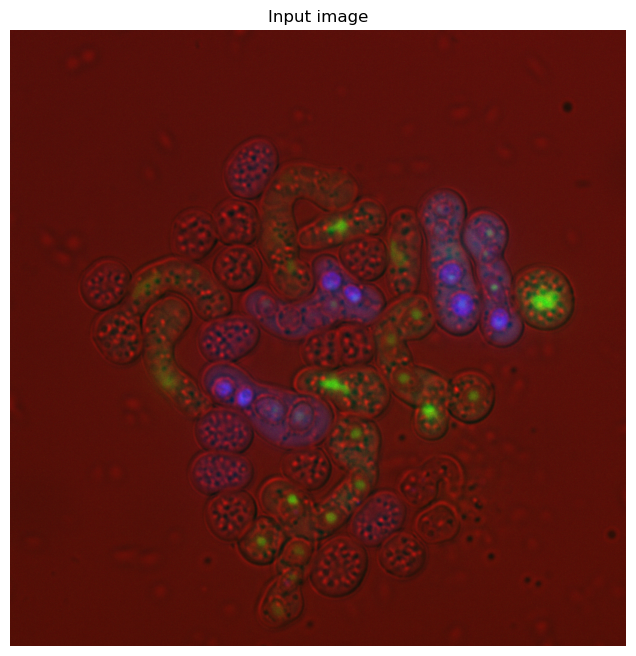

In [15]:
image_path = "./10040_leftImg8bit.png"
im = imread(image_path)
image = convert_to_rgb(im)
show_image(image, title="Input image")

## Run prediction

In [16]:
prediction_output = predictor(image)
instances = prediction_output["instances"]
panoptic_seg, _ = prediction_output["panoptic_seg"]

scores = [1] + list(instances.scores.to("cpu"))

segments_info = []
for i, panoptic_label in enumerate(np.unique(panoptic_seg.to("cpu").numpy())[1:]):
    if panoptic_label == -1:
        # VOID region
        continue
    segments_info.append({
        "id": int(panoptic_label),
        "category_id": int(panoptic_label // 1000),
        "isthing": i != 0,
        "score": float(scores[i]),
    })


## Show the panoptic segmentation mask

{0: {'id': 0, 'category_id': 0, 'isthing': False, 'score': 1.0}, 1001: {'id': 1001, 'category_id': 1, 'isthing': True, 'score': 0.9804139733314514}, 1002: {'id': 1002, 'category_id': 1, 'isthing': True, 'score': 0.9777680039405823}, 1003: {'id': 1003, 'category_id': 1, 'isthing': True, 'score': 0.978103518486023}, 1004: {'id': 1004, 'category_id': 1, 'isthing': True, 'score': 0.968609094619751}, 1005: {'id': 1005, 'category_id': 1, 'isthing': True, 'score': 0.9707242250442505}, 1006: {'id': 1006, 'category_id': 1, 'isthing': True, 'score': 0.964819610118866}, 1007: {'id': 1007, 'category_id': 1, 'isthing': True, 'score': 0.9706314206123352}, 1008: {'id': 1008, 'category_id': 1, 'isthing': True, 'score': 1.0003526210784912}, 1009: {'id': 1009, 'category_id': 1, 'isthing': True, 'score': 0.9747264981269836}, 1010: {'id': 1010, 'category_id': 1, 'isthing': True, 'score': 0.9811213612556458}, 1011: {'id': 1011, 'category_id': 1, 'isthing': True, 'score': 0.9225064516067505}, 1012: {'id': 1

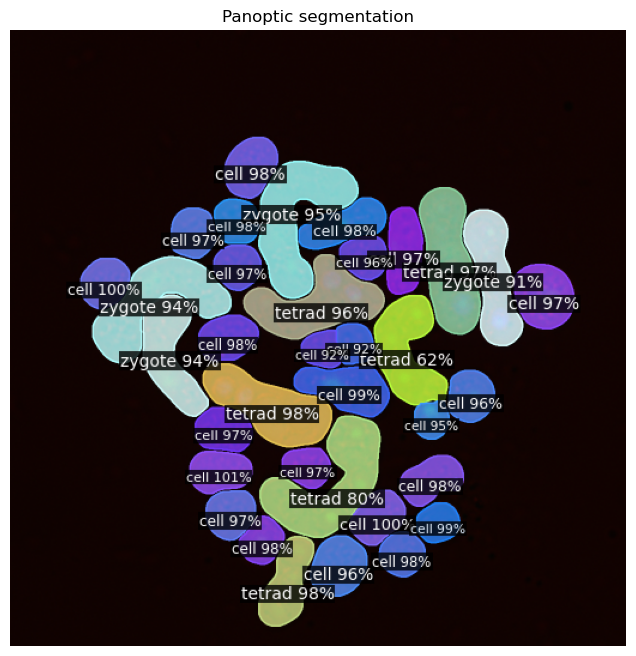

In [17]:
v = Visualizer(image[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=0.5)
out = v.draw_panoptic_seg(panoptic_seg.to("cpu"), segments_info, area_threshold=20.0, alpha=0.8)
show_image(out.get_image()[:, :, ::-1], title="Panoptic segmentation")


## Show instance predictions

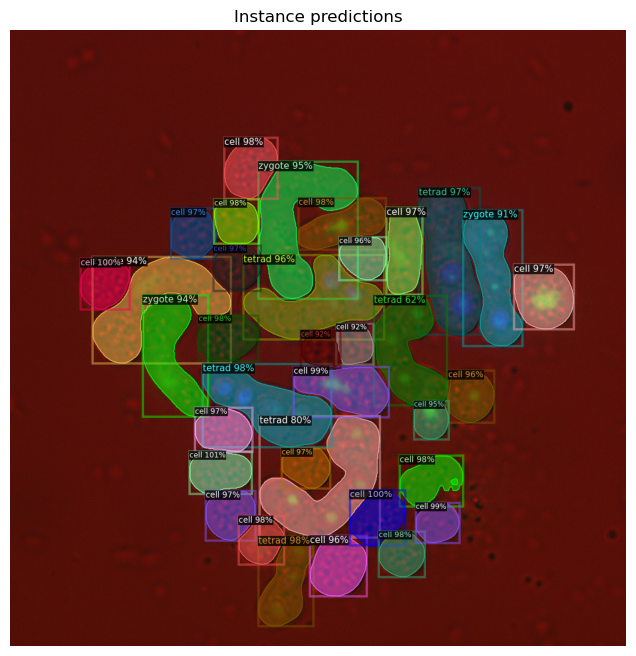

In [18]:
v = Visualizer(image[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1)
out = v.draw_instance_predictions(instances.to("cpu"), segments_info)
show_image(out.get_image()[:, :, ::-1], title="Instance predictions")
